In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

print("Libraries imported successfully!")

Libraries imported successfully!


In [5]:
from pathlib import Path

current_dir = Path.cwd()

if (current_dir / "results" / "features.csv").exists():
    project_dir = current_dir

elif (current_dir.parent / "results" / "features.csv").exists():
    project_dir = current_dir.parent

else:
    raise FileNotFoundError("features.csv not found. Check your project path.")

csv_path = project_dir / "results" / "features.csv"

df = pd.read_csv(csv_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

Dataset loaded successfully!
Dataset shape: (1537, 12)


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1537 entries, 0 to 1536
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   filename      1537 non-null   str    
 1   Mean          1537 non-null   float64
 2   Std           1537 non-null   float64
 3   RMS           1537 non-null   float64
 4   Variance      1537 non-null   float64
 5   Maximum       1537 non-null   float64
 6   Minimum       1537 non-null   float64
 7   Peak_to_Peak  1537 non-null   float64
 8   Skewness      1537 non-null   float64
 9   Kurtosis      1537 non-null   float64
 10  Crest_Factor  1537 non-null   float64
 11  Label         1537 non-null   str    
dtypes: float64(10), str(2)
memory usage: 144.2 KB


In [7]:
df.head()

,filename,Mean,Std,RMS,Variance,Maximum,Minimum,Peak_to_Peak,Skewness,Kurtosis,Crest_Factor,Label
0,100.mat,0.012531,0.066419,0.067591,0.004411,0.225305,-0.209450,0.434754,-0.075924,-0.105605,3.333365,Normal
1,100.mat,0.012378,0.064499,0.065676,0.004160,0.221967,-0.190674,0.412641,-0.129917,-0.159895,3.379705,Normal
2,100.mat,0.013284,0.062348,0.063747,0.003887,0.181287,-0.172525,0.353812,-0.041127,-0.199957,2.843829,Normal
3,100.mat,0.011395,0.063954,0.064961,0.004090,0.194638,-0.209450,0.404088,-0.191118,-0.091529,3.224227,Normal
4,100.mat,0.011194,0.065106,0.066062,0.004239,0.228434,-0.195055,0.423489,-0.047134,-0.003992,3.457885,Normal


In [8]:
print(df["Label"].value_counts())

Label
Normal              828
Inner Race Fault    237
Ball Fault          236
Outer Race Fault    236
Name: count, dtype: int64


In [9]:
print("MISSING VALUES")
print(df.isnull().sum())

MISSING VALUES
filename        0
Mean            0
Std             0
RMS             0
Variance        0
Maximum         0
Minimum         0
Peak_to_Peak    0
Skewness        0
Kurtosis        0
Crest_Factor    0
Label           0
dtype: int64


In [10]:
numeric_df = df.select_dtypes(include=np.number)

print("INFINITE VALUES")
print(np.isinf(numeric_df).sum())

INFINITE VALUES
Mean            0
Std             0
RMS             0
Variance        0
Maximum         0
Minimum         0
Peak_to_Peak    0
Skewness        0
Kurtosis        0
Crest_Factor    0
dtype: int64


In [12]:

file_counts = df.groupby(
    ["filename", "Label"]
).size().reset_index(name="Segments")

print(file_counts)

   filename             Label  Segments
0   100.mat            Normal       237
1   105.mat  Inner Race Fault        59
2   106.mat  Inner Race Fault        59
3   107.mat  Inner Race Fault        59
4   108.mat  Inner Race Fault        60
5   118.mat        Ball Fault        59
6   119.mat        Ball Fault        59
7   120.mat        Ball Fault        59
8   121.mat        Ball Fault        59
9   130.mat  Outer Race Fault        59
10  131.mat  Outer Race Fault        59
11  132.mat  Outer Race Fault        59
12  133.mat  Outer Race Fault        59
13   97.mat            Normal       119
14   98.mat            Normal       236
15   99.mat            Normal       236


In [16]:
# Create EDA result folders

eda_dir = project_dir / "results" / "eda"

graphs_dir = eda_dir / "graphs"

eda_dir.mkdir(parents=True, exist_ok=True)

graphs_dir.mkdir(parents=True, exist_ok=True)

print("EDA folders created successfully!")

EDA folders created successfully!


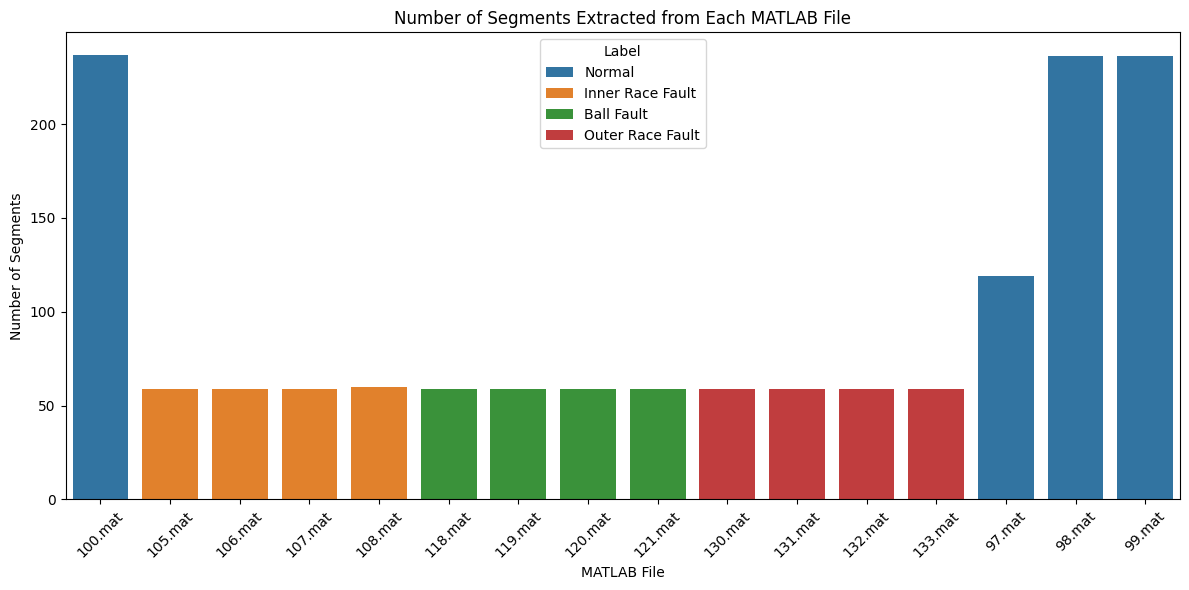

In [17]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=file_counts,
    x="filename",
    y="Segments",
    hue="Label"
)

plt.title("Number of Segments Extracted from Each MATLAB File")
plt.xlabel("MATLAB File")
plt.ylabel("Number of Segments")

plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(
    graphs_dir / "file_wise_distribution.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [18]:
print("Total duplicate rows:", df.duplicated().sum())

Total duplicate rows: 0


In [19]:
df.describe()

,Mean,Std,RMS,Variance,Maximum,Minimum,Peak_to_Peak,Skewness,Kurtosis,Crest_Factor
count,1537.000000,1537.000000,1537.000000,1537.000000,1537.000000,1537.000000,1537.000000,1537.000000,1537.000000,1537.000000
mean,0.010192,0.196446,0.197167,0.075429,0.865239,-0.814061,1.679300,-0.055753,1.037358,3.806967
std,0.005072,0.191995,0.191592,0.128432,0.995637,0.943517,1.936100,0.120018,1.834640,0.784625
min,0.002703,0.059126,0.060376,0.003496,0.157296,-3.408701,0.342546,-0.378156,-0.560307,2.646803
25%,0.004785,0.065107,0.066273,0.004239,0.207155,-1.196335,0.413267,-0.151886,-0.158257,3.187306
50%,0.011171,0.072793,0.073935,0.005299,0.243871,-0.241368,0.471054,-0.040209,-0.026103,3.464383
75%,0.013566,0.293562,0.293822,0.086179,1.398891,-0.203400,2.621053,0.030379,2.329891,4.629839
max,0.034367,0.714569,0.714804,0.510608,3.630425,-0.160217,6.756895,0.225839,5.688980,5.925084


In [20]:
features = [
    "Mean",
    "Std",
    "RMS",
    "Variance",
    "Maximum",
    "Minimum",
    "Peak_to_Peak",
    "Skewness",
    "Kurtosis",
    "Crest_Factor"
]

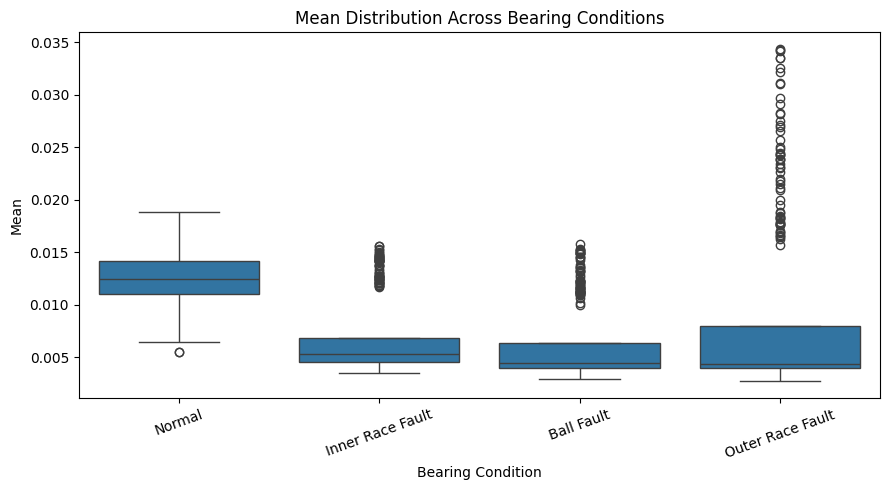

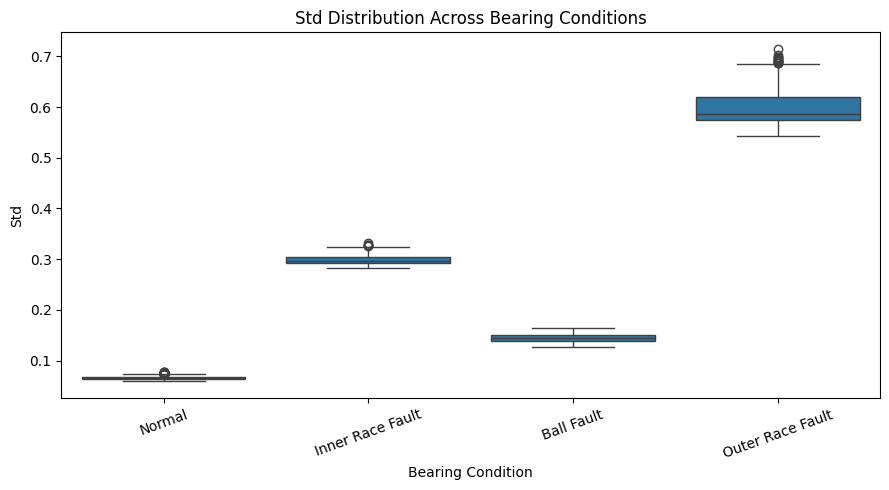

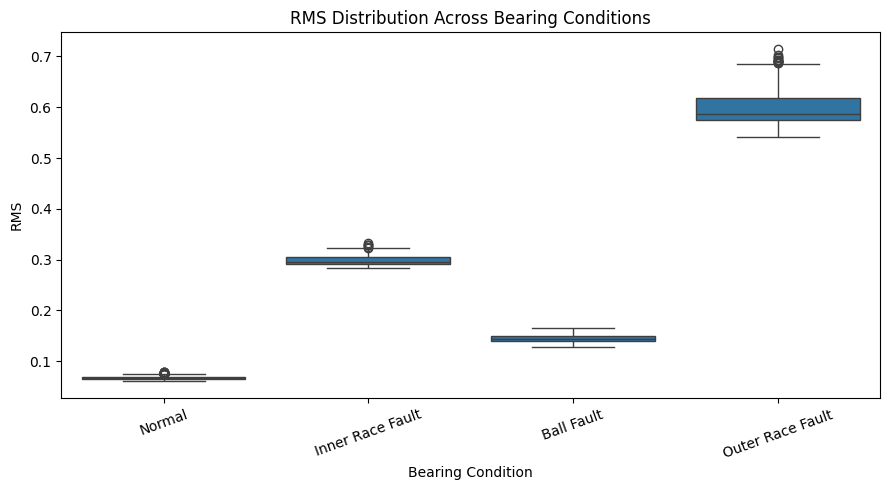

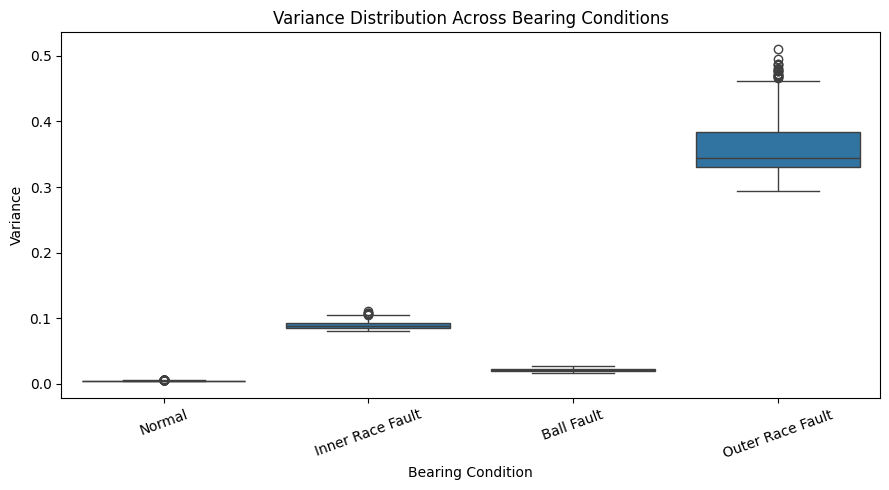

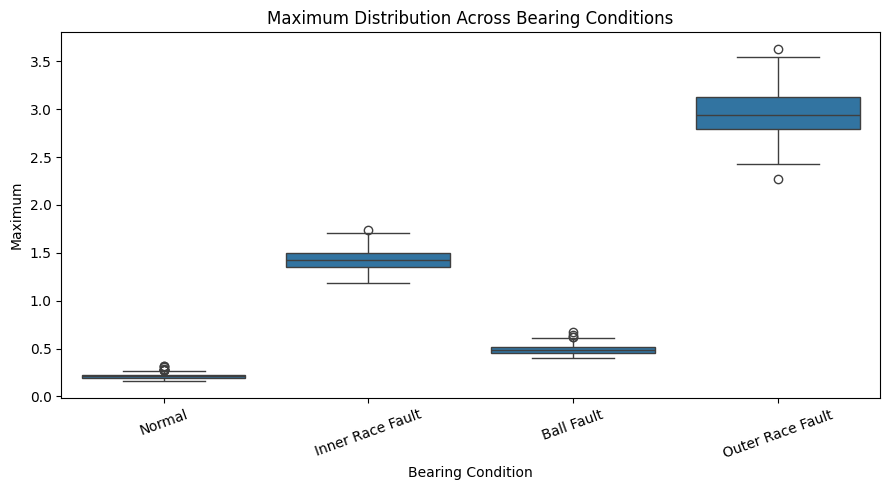

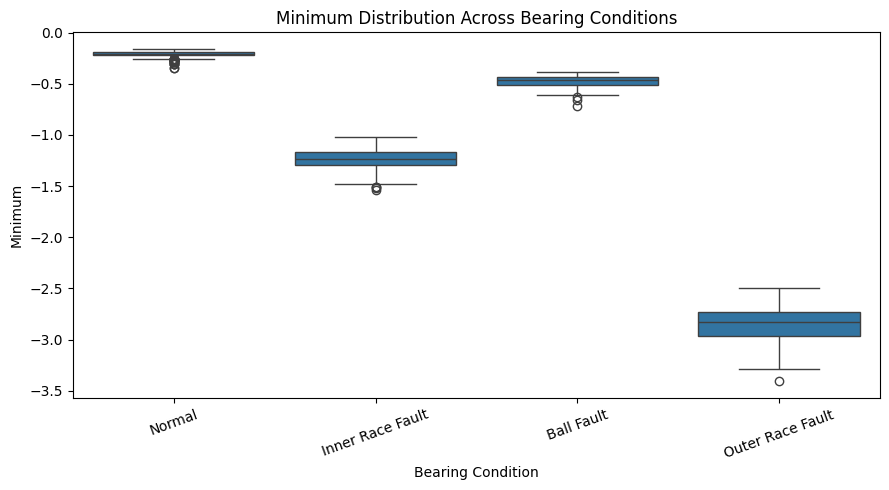

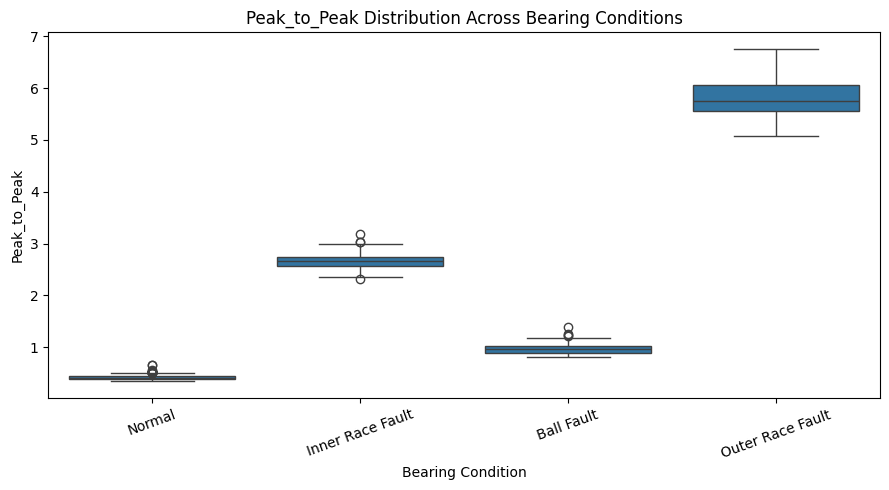

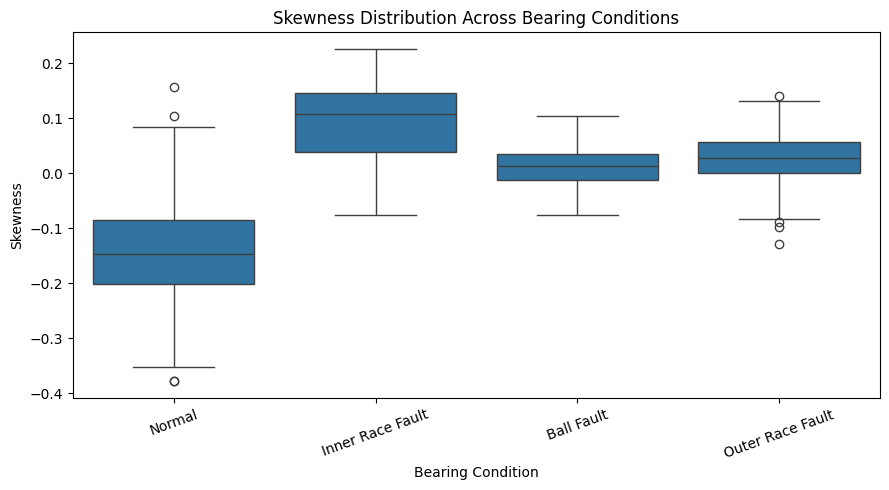

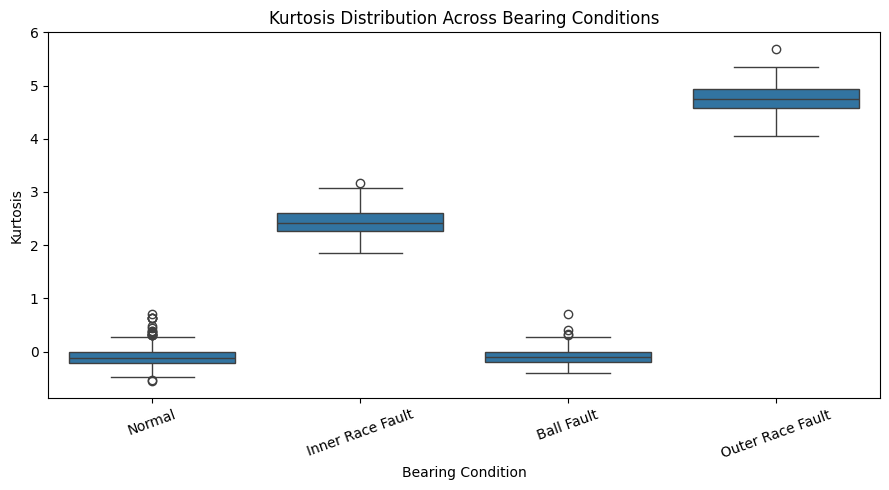

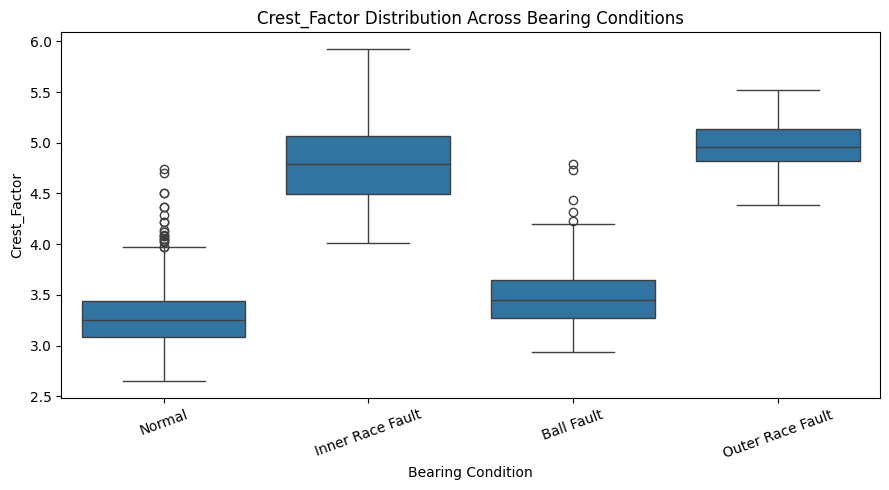

In [21]:
for feature in features:

    plt.figure(figsize=(9, 5))

    sns.boxplot(
        data=df,
        x="Label",
        y=feature
    )

    plt.title(f"{feature} Distribution Across Bearing Conditions")

    plt.xlabel("Bearing Condition")
    plt.ylabel(feature)

    plt.xticks(rotation=20)

    plt.tight_layout()

    plt.savefig(
        graphs_dir / f"{feature}_boxplot.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

In [22]:
important_features = [
    "RMS",
    "Kurtosis",
    "Skewness",
    "Crest_Factor"
]

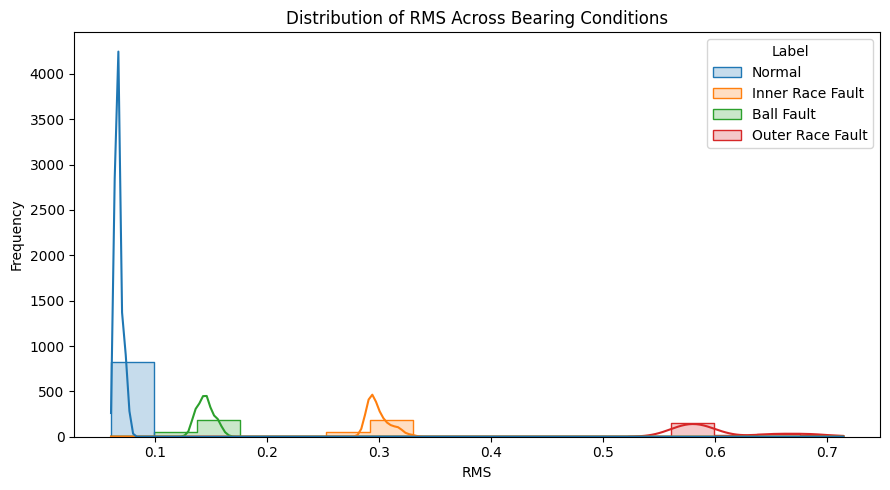

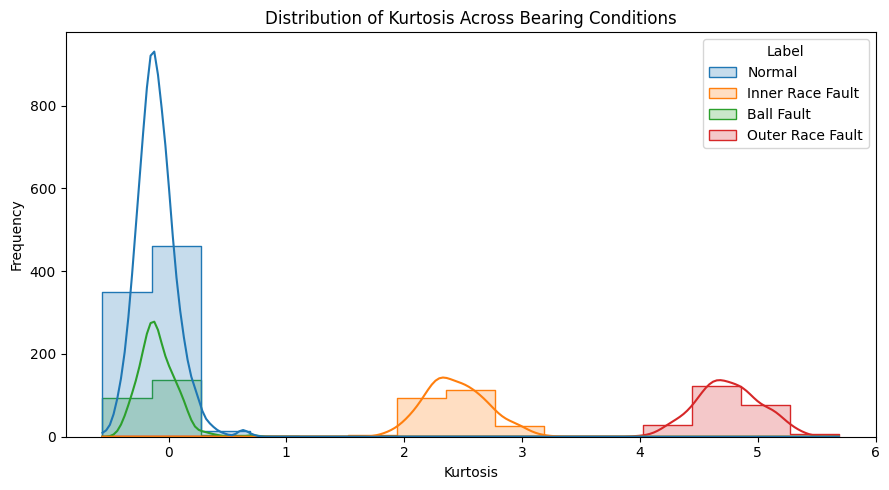

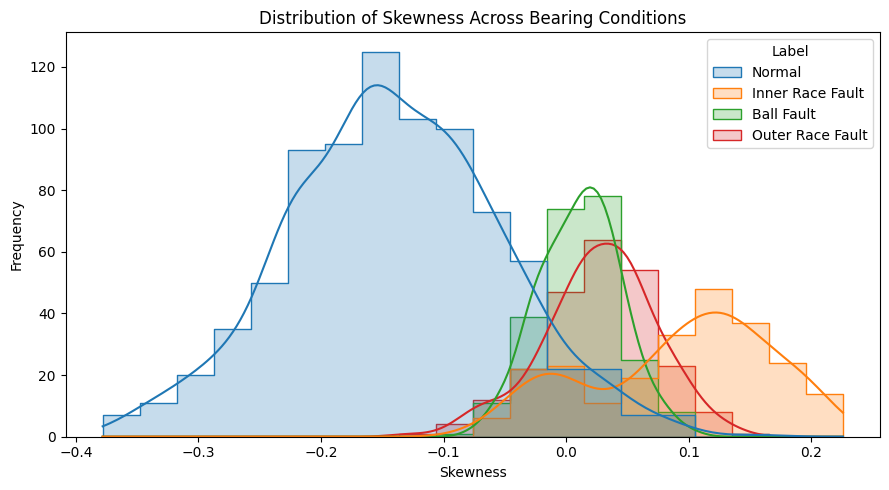

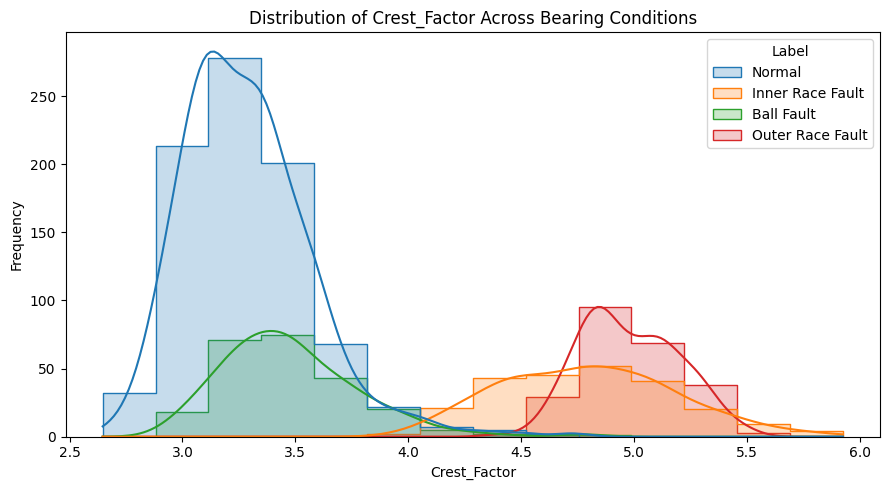

In [23]:
for feature in important_features:

    plt.figure(figsize=(9, 5))

    sns.histplot(
        data=df,
        x=feature,
        hue="Label",
        kde=True,
        element="step",
        common_norm=False
    )

    plt.title(f"Distribution of {feature} Across Bearing Conditions")

    plt.xlabel(feature)
    plt.ylabel("Frequency")

    plt.tight_layout()

    plt.savefig(
        graphs_dir / f"{feature}_histogram.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

In [24]:
features = [
    "Mean",
    "Std",
    "RMS",
    "Variance",
    "Maximum",
    "Minimum",
    "Peak_to_Peak",
    "Skewness",
    "Kurtosis",
    "Crest_Factor"
]

In [25]:
correlation = df[features].corr()

print(correlation)

                  Mean       Std       RMS  Variance   Maximum   Minimum  \
Mean          1.000000 -0.223094 -0.221148 -0.094781 -0.203994  0.217913   
Std          -0.223094  1.000000  0.999997  0.975789  0.995507 -0.995842   
RMS          -0.221148  0.999997  1.000000  0.976148  0.995569 -0.995929   
Variance     -0.094781  0.975789  0.976148  1.000000  0.972308 -0.981078   
Maximum      -0.203994  0.995507  0.995569  0.972308  1.000000 -0.993700   
Minimum       0.217913 -0.995842 -0.995929 -0.981078 -0.993700  1.000000   
Peak_to_Peak -0.211099  0.997241  0.997315  0.978116  0.998507 -0.998338   
Skewness     -0.315472  0.565544  0.564546  0.439485  0.562662 -0.520648   
Kurtosis     -0.240159  0.972880  0.972963  0.936723  0.981936 -0.976660   
Crest_Factor -0.271677  0.847501  0.847206  0.759128  0.871412 -0.841342   

              Peak_to_Peak  Skewness  Kurtosis  Crest_Factor  
Mean             -0.211099 -0.315472 -0.240159     -0.271677  
Std               0.997241  0.565544 

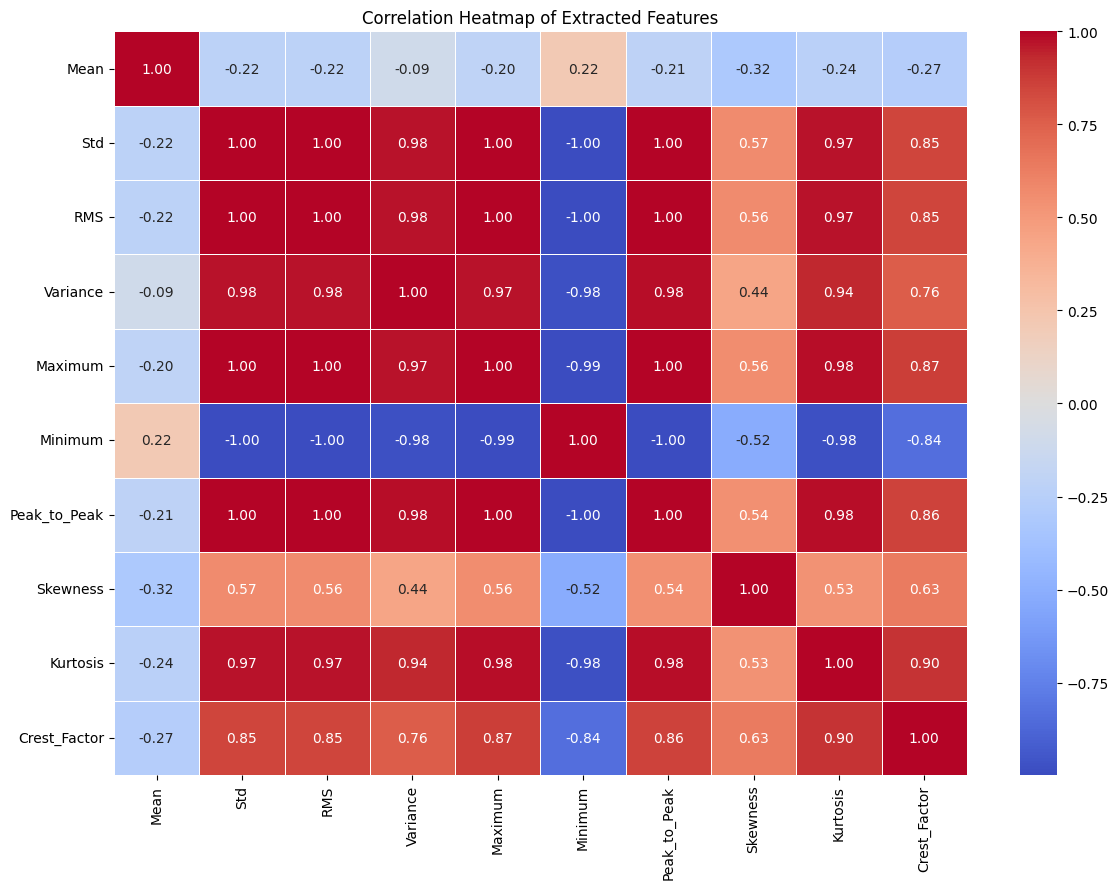

In [26]:
plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Extracted Features")

plt.tight_layout()

plt.savefig(
    graphs_dir / "correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [27]:
# Create EDA directory
eda_dir.mkdir(parents=True, exist_ok=True)

# 1. Statistical summary
df.describe().to_csv(
    eda_dir / "statistical_summary.csv"
)

# 2. Correlation matrix
correlation.to_csv(
    eda_dir / "correlation_matrix.csv"
)

# 3. Class distribution
class_counts = df["Label"].value_counts()

class_counts.to_csv(
    eda_dir / "class_distribution.csv"
)

# 4. File-wise distribution
file_counts.to_csv(
    eda_dir / "file_wise_distribution.csv",
    index=False
)

print("EDA CSV files saved successfully!")

EDA CSV files saved successfully!
